In [3]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents']


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file in [
            "clean_cifar10_predictions.npz",
            "baseline_resnet18_cifar10.pth",
            "gaussian_noise_severity1_predictions.npz"
        ]:
            print(os.path.join(root, file))

/kaggle/input/datasets/kimi11/clean-cifar10-predictions/clean_cifar10_predictions.npz
/kaggle/input/datasets/kimi11/checkpoint/baseline_resnet18_cifar10.pth
/kaggle/input/datasets/kimi11/gaussian-noise-severity1-predictions/gaussian_noise_severity1_predictions.npz


In [5]:

import numpy as np
import os

clean_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "clean_cifar10_predictions.npz" in files:
        clean_path = os.path.join(
            root, "clean_cifar10_predictions.npz"
        )
        break

if clean_path is None:
    raise FileNotFoundError(
        "clean_cifar10_predictions.npz was not found."
    )

clean_data = np.load(clean_path)

print("File:", clean_path)
print("Available arrays:", clean_data.files)

for key in clean_data.files:
    print(key, clean_data[key].shape)


File: /kaggle/input/datasets/kimi11/clean-cifar10-predictions/clean_cifar10_predictions.npz
Available arrays: ['probabilities', 'labels', 'confidences', 'correct']
probabilities (10000, 10)
labels (10000,)
confidences (10000,)
correct (10000,)


In [6]:

import numpy as np

print("Available arrays:", clean_data.files)


Available arrays: ['probabilities', 'labels', 'confidences', 'correct']


In [7]:

import numpy as np
import pandas as pd

probabilities = clean_data["probabilities"]
labels = clean_data["labels"]
confidences = clean_data["confidences"]
correct = clean_data["correct"].astype(bool)

accuracy = correct.mean()
mean_confidence = confidences.mean()

# Expected Calibration Error (15 bins)
n_bins = 15
bin_edges = np.linspace(0, 1, n_bins + 1)
ece = 0.0

for i in range(n_bins):
    if i == n_bins - 1:
        mask = (confidences >= bin_edges[i]) & (
            confidences <= bin_edges[i + 1]
        )
    else:
        mask = (confidences >= bin_edges[i]) & (
            confidences < bin_edges[i + 1]
        )

    if mask.any():
        bin_accuracy = correct[mask].mean()
        bin_confidence = confidences[mask].mean()
        ece += mask.mean() * abs(
            bin_accuracy - bin_confidence
        )

# Multiclass Brier score
one_hot = np.eye(probabilities.shape[1])[labels.astype(int)]
brier_score = np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))

clean_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Mean confidence (%)",
        "ECE (15 bins)",
        "Multiclass Brier score"
    ],
    "Value": [
        accuracy * 100,
        mean_confidence * 100,
        ece,
        brier_score
    ]
})

display(clean_metrics.round(4))


,Metric,Value
0,Accuracy (%),81.4500
1,Mean confidence (%),88.0163
2,ECE (15 bins),0.0657
3,Multiclass Brier score,0.2727


In [8]:

clean_metrics.to_csv(
    "/kaggle/working/fdcc_clean_calibration_metrics.csv",
    index=False
)

print("Saved clean calibration metrics.")


Saved clean calibration metrics.


In [9]:

import numpy as np
import pandas as pd

bin_edges = np.linspace(0, 1, 16)
reliability_rows = []

for i in range(15):
    if i == 14:
        mask = (confidences >= bin_edges[i]) & (
            confidences <= bin_edges[i + 1]
        )
    else:
        mask = (confidences >= bin_edges[i]) & (
            confidences < bin_edges[i + 1]
        )

    if mask.any():
        reliability_rows.append({
            "bin_lower": bin_edges[i],
            "bin_upper": bin_edges[i + 1],
            "sample_count": int(mask.sum()),
            "mean_confidence": confidences[mask].mean(),
            "accuracy": correct[mask].mean()
        })

reliability_df = pd.DataFrame(reliability_rows)
display(reliability_df.round(4))


,bin_lower,bin_upper,sample_count,mean_confidence,accuracy
0,0.1333,0.2000,1,0.1952,0.0000
1,0.2000,0.2667,11,0.2474,0.1818
2,0.2667,0.3333,61,0.3072,0.2459
3,0.3333,0.4000,128,0.3743,0.3047
4,0.4000,0.4667,211,0.4367,0.3602
5,0.4667,0.5333,346,0.5036,0.4595
6,0.5333,0.6000,398,0.5666,0.4899
7,0.6000,0.6667,376,0.6331,0.5452
8,0.6667,0.7333,426,0.7004,0.5775
9,0.7333,0.8000,455,0.7679,0.6747


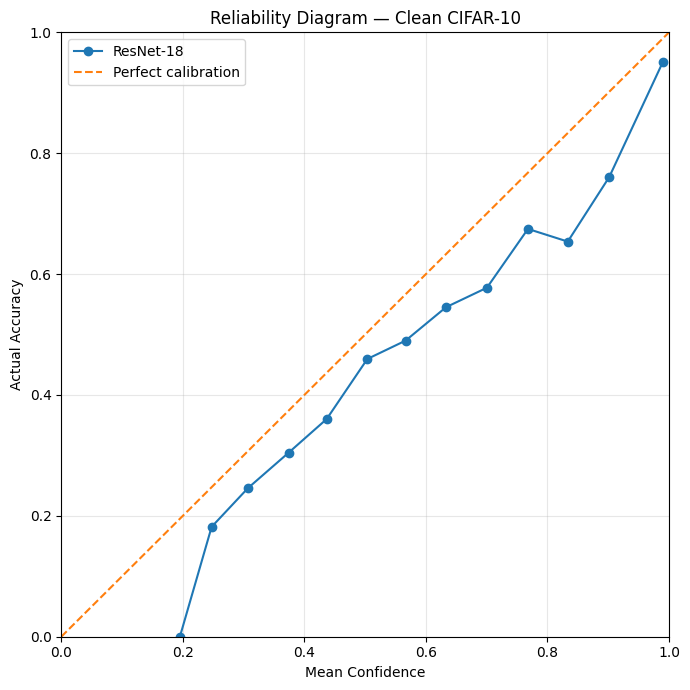

In [10]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 7))

plt.plot(
    reliability_df["mean_confidence"],
    reliability_df["accuracy"],
    marker="o",
    label="ResNet-18"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Reliability Diagram — Clean CIFAR-10")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/fdcc_clean_reliability.png",
    dpi=300
)
plt.show()


How to read it:
- The diagonal represents perfect calibration.
- Points below the diagonal indicate overconfidence.
- Points above the diagonal indicate underconfidence


In [11]:

import os

noisy_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "gaussian_noise_severity1_predictions.npz" in files:
        noisy_path = os.path.join(
            root, "gaussian_noise_severity1_predictions.npz"
        )
        break

if noisy_path:
    print("Found:", noisy_path)
else:
    print("Gaussian-noise prediction file not found in Kaggle inputs.")


Found: /kaggle/input/datasets/kimi11/gaussian-noise-severity1-predictions/gaussian_noise_severity1_predictions.npz


In [12]:

noisy_data = np.load(noisy_path)

print("File:", noisy_path)
print("Available arrays:", noisy_data.files)

for key in noisy_data.files:
    print(key, noisy_data[key].shape)


File: /kaggle/input/datasets/kimi11/gaussian-noise-severity1-predictions/gaussian_noise_severity1_predictions.npz
Available arrays: ['probabilities', 'labels', 'confidences', 'correct']
probabilities (10000, 10)
labels (10000,)
confidences (10000,)
correct (10000,)


In [13]:

noisy_probabilities = noisy_data["probabilities"]
noisy_labels = noisy_data["labels"]
noisy_confidences = noisy_data["confidences"]
noisy_correct = noisy_data["correct"].astype(bool)

noisy_accuracy = noisy_correct.mean()
noisy_mean_confidence = noisy_confidences.mean()

# ECE using 15 bins
bin_edges = np.linspace(0, 1, 16)
noisy_ece = 0.0

for i in range(15):
    if i == 14:
        mask = (noisy_confidences >= bin_edges[i]) & (
            noisy_confidences <= bin_edges[i + 1]
        )
    else:
        mask = (noisy_confidences >= bin_edges[i]) & (
            noisy_confidences < bin_edges[i + 1]
        )

    if mask.any():
        bin_accuracy = noisy_correct[mask].mean()
        bin_confidence = noisy_confidences[mask].mean()
        noisy_ece += mask.mean() * abs(
            bin_accuracy - bin_confidence
        )

# Multiclass Brier score
noisy_one_hot = np.eye(
    noisy_probabilities.shape[1]
)[noisy_labels.astype(int)]

noisy_brier = np.mean(
    np.sum((noisy_probabilities - noisy_one_hot) ** 2, axis=1)
)

noisy_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Mean confidence (%)",
        "ECE (15 bins)",
        "Multiclass Brier score"
    ],
    "Value": [
        noisy_accuracy * 100,
        noisy_mean_confidence * 100,
        noisy_ece,
        noisy_brier
    ]
})

display(noisy_metrics.round(4))


,Metric,Value
0,Accuracy (%),71.8100
1,Mean confidence (%),84.9557
2,ECE (15 bins),0.1317
3,Multiclass Brier score,0.4243


In [14]:

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Mean confidence (%)",
        "ECE (15 bins)",
        "Multiclass Brier score"
    ],
    "Clean CIFAR-10": [
        accuracy * 100,
        mean_confidence * 100,
        ece,
        brier_score
    ],
    "Gaussian Noise (Severity 1)": [
        noisy_accuracy * 100,
        noisy_mean_confidence * 100,
        noisy_ece,
        noisy_brier
    ]
})

comparison_df["Change (Noisy - Clean)"] = (
    comparison_df["Gaussian Noise (Severity 1)"]
    - comparison_df["Clean CIFAR-10"]
)

display(comparison_df.round(4))

comparison_df.to_csv(
    "/kaggle/working/fdcc_clean_vs_noisy_calibration.csv",
    index=False
)


,Metric,Clean CIFAR-10,Gaussian Noise (Severity 1),Change (Noisy - Clean)
0,Accuracy (%),81.4500,71.8100,-9.6400
1,Mean confidence (%),88.0163,84.9557,-3.0605
2,ECE (15 bins),0.0657,0.1317,0.0660
3,Multiclass Brier score,0.2727,0.4243,0.1516


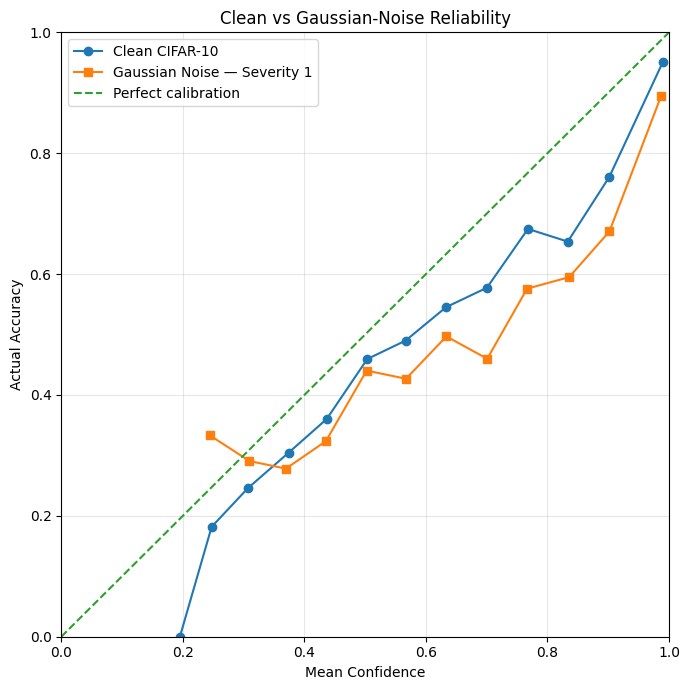

In [15]:

import matplotlib.pyplot as plt
import numpy as np

def get_reliability_data(confidences, correct, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1)
    mean_conf, accuracies = [], []

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidences >= edges[i]) & (
                confidences <= edges[i + 1]
            )
        else:
            mask = (confidences >= edges[i]) & (
                confidences < edges[i + 1]
            )

        if mask.any():
            mean_conf.append(confidences[mask].mean())
            accuracies.append(correct[mask].mean())

    return mean_conf, accuracies

clean_conf, clean_acc = get_reliability_data(
    confidences, correct
)
noisy_conf, noisy_acc = get_reliability_data(
    noisy_confidences, noisy_correct
)

plt.figure(figsize=(7, 7))
plt.plot(
    clean_conf, clean_acc,
    marker="o", label="Clean CIFAR-10"
)
plt.plot(
    noisy_conf, noisy_acc,
    marker="s", label="Gaussian Noise — Severity 1"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Perfect calibration"
)

plt.xlabel("Mean Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Clean vs Gaussian-Noise Reliability")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/fdcc_clean_vs_noisy_reliability.png",
    dpi=300
)
plt.show()


In [16]:

accuracy_change = noisy_accuracy * 100 - accuracy * 100
confidence_change = noisy_mean_confidence * 100 - mean_confidence * 100
ece_change = noisy_ece - ece
brier_change = noisy_brier - brier_score

print("CALIBRATION ANALYSIS SUMMARY")
print("-" * 40)
print(f"Clean accuracy:       {accuracy * 100:.2f}%")
print(f"Noisy accuracy:       {noisy_accuracy * 100:.2f}%")
print(f"Accuracy change:      {accuracy_change:+.2f} percentage points")
print()
print(f"Clean mean confidence: {mean_confidence * 100:.2f}%")
print(f"Noisy mean confidence: {noisy_mean_confidence * 100:.2f}%")
print(f"Confidence change:     {confidence_change:+.2f} percentage points")
print()
print(f"Clean ECE:             {ece:.4f}")
print(f"Noisy ECE:             {noisy_ece:.4f}")
print(f"ECE change:            {ece_change:+.4f}")
print()
print(f"Clean Brier score:     {brier_score:.4f}")
print(f"Noisy Brier score:     {noisy_brier:.4f}")
print(f"Brier change:          {brier_change:+.4f}")


CALIBRATION ANALYSIS SUMMARY
----------------------------------------
Clean accuracy:       81.45%
Noisy accuracy:       71.81%
Accuracy change:      -9.64 percentage points

Clean mean confidence: 88.02%
Noisy mean confidence: 84.96%
Confidence change:     -3.06 percentage points

Clean ECE:             0.0657
Noisy ECE:             0.1317
ECE change:            +0.0660

Clean Brier score:     0.2727
Noisy Brier score:     0.4243
Brier change:          +0.1516


# Notebook 05 — Calibration Analysis

## Objective

The objective of this notebook is to evaluate the confidence calibration of the trained ResNet-18 CIFAR-10 classifier and investigate how Gaussian-noise corruption affects its calibration.

This notebook establishes a calibration baseline before evaluating calibration methods such as temperature scaling and the proposed feature-distance-guided approach.

## Experimental Setup

- **Model:** Previously trained CIFAR-adapted ResNet-18
- **Dataset 1:** Clean CIFAR-10 test set
- **Dataset 2:** CIFAR-10-C Gaussian noise, severity 1
- **Evaluation:** Saved model predictions; no model retraining
- **Calibration metric:** Expected Calibration Error (ECE), using 15 bins
- **Additional metrics:** Classification accuracy, mean prediction confidence, and multiclass Brier score

## Results

| Metric | Clean CIFAR-10 | Gaussian Noise, Severity 1 |
|---|---:|---:|
| Accuracy | 81.45% | 71.81% |
| Mean confidence | 88.02% | 84.96% |
| ECE (15 bins) | 0.0657 | 0.1317 |
| Multiclass Brier score | 0.2727 | 0.4243 |

## Key Observations

1. **Reduced classification accuracy:** Accuracy decreased from 81.45% on clean data to 71.81% under Gaussian noise, a decline of 9.64 percentage points.

2. **Increased calibration error:** ECE increased from 0.0657 to 0.1317, indicating a larger confidence–accuracy discrepancy across the evaluated confidence bins.

3. **Worse probabilistic predictions:** The multiclass Brier score increased from 0.2727 to 0.4243. Since lower Brier scores are better, this indicates degraded probabilistic prediction quality.

4. **Lower mean confidence:** Mean confidence decreased from 88.02% to 84.96%. Despite this decrease, the model's calibration worsened, showing that mean confidence alone is insufficient to assess calibration quality.

5. **Reliability analysis:** Reliability diagrams were generated to compare predicted confidence with empirical accuracy on clean and corrupted data.

## Conclusion

The results indicate that Gaussian noise at severity 1 degrades both classification performance and calibration quality for the existing ResNet-18 classifier.

The increase in ECE and Brier score provides a baseline against which calibration methods can be evaluated. However, these results do not establish that feature-distance-guided calibration will improve calibration; that hypothesis requires a separate controlled experiment.

## Limitations

- The corruption analysis reported here covers Gaussian noise at severity 1, not every corruption type or severity.
- ECE depends on the selected number and placement of confidence bins.
- These results describe one trained model checkpoint and do not establish variation across training seeds.
- No calibration method was fitted or evaluated in this notebook.

## Next Steps

1. Evaluate standard temperature scaling as a calibration baseline.
2. Fit the calibration parameter using a designated clean validation set, not the test set.
3. Evaluate the fitted method on clean test data and corrupted test data.
4. Compare accuracy, ECE, Brier score, and reliability diagrams before and after calibration.
5. Evaluate the proposed feature-distance-guided method under the same protocol and compare it directly against the uncalibrated model and temperature scaling.

## Output Artifacts

- `fdcc_clean_calibration_metrics.csv`
- `fdcc_clean_reliability.png`
- `fdcc_clean_vs_noisy_calibration.csv`
- `fdcc_clean_vs_noisy_reliability.png`

These files record the baseline metrics, clean reliability analysis, and clean-versus-corrupted comparison. Confirm that each file was generated successfully before treating it as a saved artifact.
